# Exploração e Visualização das Funções de Ativação (Lotes 1 e 2)

Este notebook testa a chamada, valida a estabilidade numérica e visualiza as **8 funções de ativação distintas** implementadas em `mlp.ativacoes`:

### Lote 1:
1. **Sigmoide** — $f(z) = \frac{1}{1 + e^{-z}}$, derivada $f'(z) = f(z)(1 - f(z))$
2. **LeakyReLU (e ReLU)** — $f(z) = \max(\alpha z, z)$, derivada $f'(z) = 1$ se $z > 0$ senão $\alpha$
3. **Swish (SiLU)** — $f(z) = z \cdot \sigma(z)$, derivada $f'(z) = f(z) + \sigma(z)(1 - f(z))$
4. **Softmax** — $S(z_i) = \frac{e^{z_i - \max(z)}}{\sum_j e^{z_j - \max(z)}}$ com backward via produto vetor-Jacobiana

### Lote 2:
5. **Tanh (Analítica)** — $\tanh(z) = 2\sigma(2z) - 1$, derivada $f'(z) = 1 - \tanh^2(z)$ (sem `np.tanh`)
6. **ELU** — $f(z) = z$ se $z > 0$ senão $\alpha(e^z - 1)$, derivada $f'(z) = 1$ se $z > 0$ senão $f(z) + \alpha$
7. **Softplus** — $f(z) = \ln(1 + e^z)$, derivada $f'(z) = \sigma(z)$
8. **Softsign** — $f(z) = \frac{z}{1 + |z|}$, derivada $f'(z) = \frac{1}{(1 + |z|)^2}$


In [4]:
import sys
from pathlib import Path

# Garante que a raiz do projeto esteja no sys.path ao rodar da pasta parciais/
raiz_projeto = Path.cwd().parent if Path.cwd().name == "parciais" else Path.cwd()
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mlp.ativacoes import (
    ELU,
    LeakyReLU,
    Sigmoide,
    Softmax,
    Softplus,
    Softsign,
    Swish,
    Tanh,
)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


## 1. Visualização das Funções de Ativação 1D (Propagação Direta)

Abaixo avaliamos o comportamento da propagação direta ($A = f(Z)$) para um domínio contínuo $z \in [-6, 6]$:
- **Sigmoide**: Comprime a reta real no intervalo $(0, 1)$, ideal para probabilidades binárias.
- **ReLU / LeakyReLU**: Mantém gradiente ativo para valores positivos e inclinação suave para negativos.
- **Swish**: Função suave e não-monotônica ($z \cdot \sigma(z)$), padrão em modelos convolucionais modernos.
- **Tanh (Analítica)**: Varia no intervalo $(-1, 1)$ com simetria ímpar e média centrada em zero.
- **ELU**: Suaviza transição para negativos com assíntota em $-\alpha$, reduzindo viés de deslocamento.
- **Softplus**: Aproximação suave e estritamente positiva da ReLU com $f(0) = \ln(2)$.
- **Softsign**: Alternativa à Tanh com decaimento polinomial mais lento e livre de exponenciais.


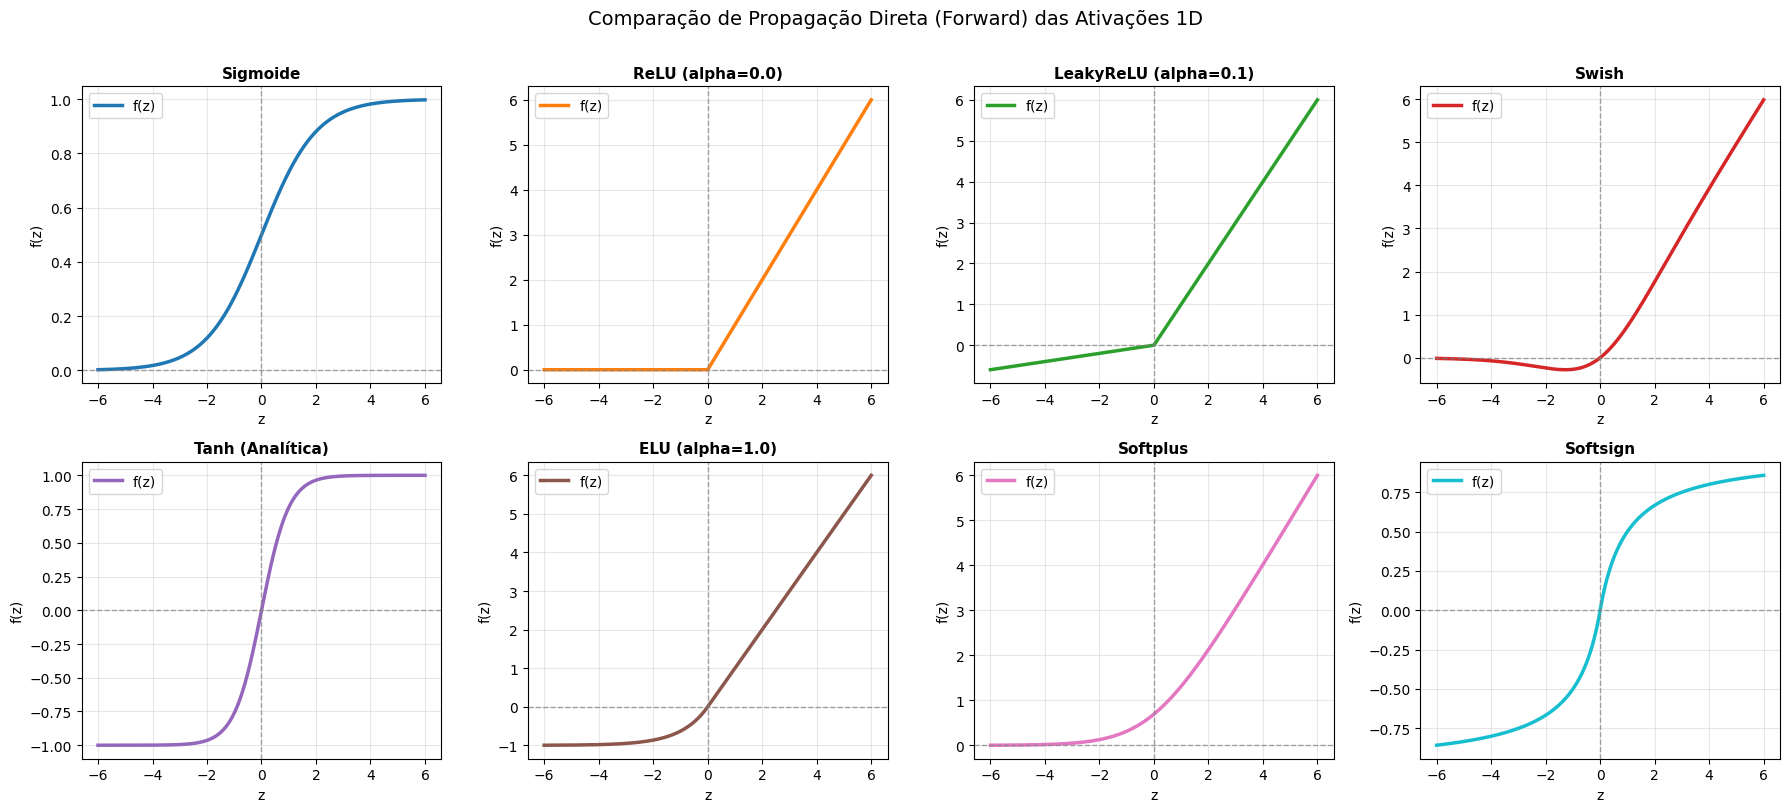

In [5]:
z = np.linspace(-6, 6, 500)
ativacoes_1d = {
    "Sigmoide": Sigmoide(),
    "ReLU (alpha=0.0)": LeakyReLU(alpha=0.0),
    "LeakyReLU (alpha=0.1)": LeakyReLU(alpha=0.1),
    "Swish": Swish(),
    "Tanh (Analítica)": Tanh(),
    "ELU (alpha=1.0)": ELU(alpha=1.0),
    "Softplus": Softplus(),
    "Softsign": Softsign(),
}

cores = {
    "Sigmoide": "#1f77b4",
    "ReLU (alpha=0.0)": "#ff7f0e",
    "LeakyReLU (alpha=0.1)": "#2ca02c",
    "Swish": "#d62728",
    "Tanh (Analítica)": "#9467bd",
    "ELU (alpha=1.0)": "#8c564b",
    "Softplus": "#e377c2",
    "Softsign": "#17becf",
}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for ax, (nome, ativ) in zip(axes, ativacoes_1d.items(), strict=True):
    a = ativ.passo_a_frente(z)
    ax.plot(z, a, lw=2.5, color=cores[nome], label="f(z)")
    ax.axhline(0, color="gray", linestyle="--", alpha=0.7, lw=1)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.7, lw=1)
    ax.set_title(nome, fontsize=11, fontweight="bold")
    ax.set_xlabel("z")
    ax.set_ylabel("f(z)")
    ax.legend(loc="upper left")

plt.suptitle("Comparação de Propagação Direta (Forward) das Ativações 1D", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


## 2. Validação das Derivadas Analíticas (Retropropagação vs. Gradiente Numérico)

Para garantir que a regra da cadeia analítica implementada em `passo_atras` está correta em todas as 8 classes, comparamos o gradiente analítico com a aproximação numérica por diferenças finitas centrais:
$$\frac{df_{\text{num}}}{dz} = \frac{f(z + \epsilon) - f(z - \epsilon)}{2\epsilon}, \quad \text{com } \epsilon = 10^{-5}$$


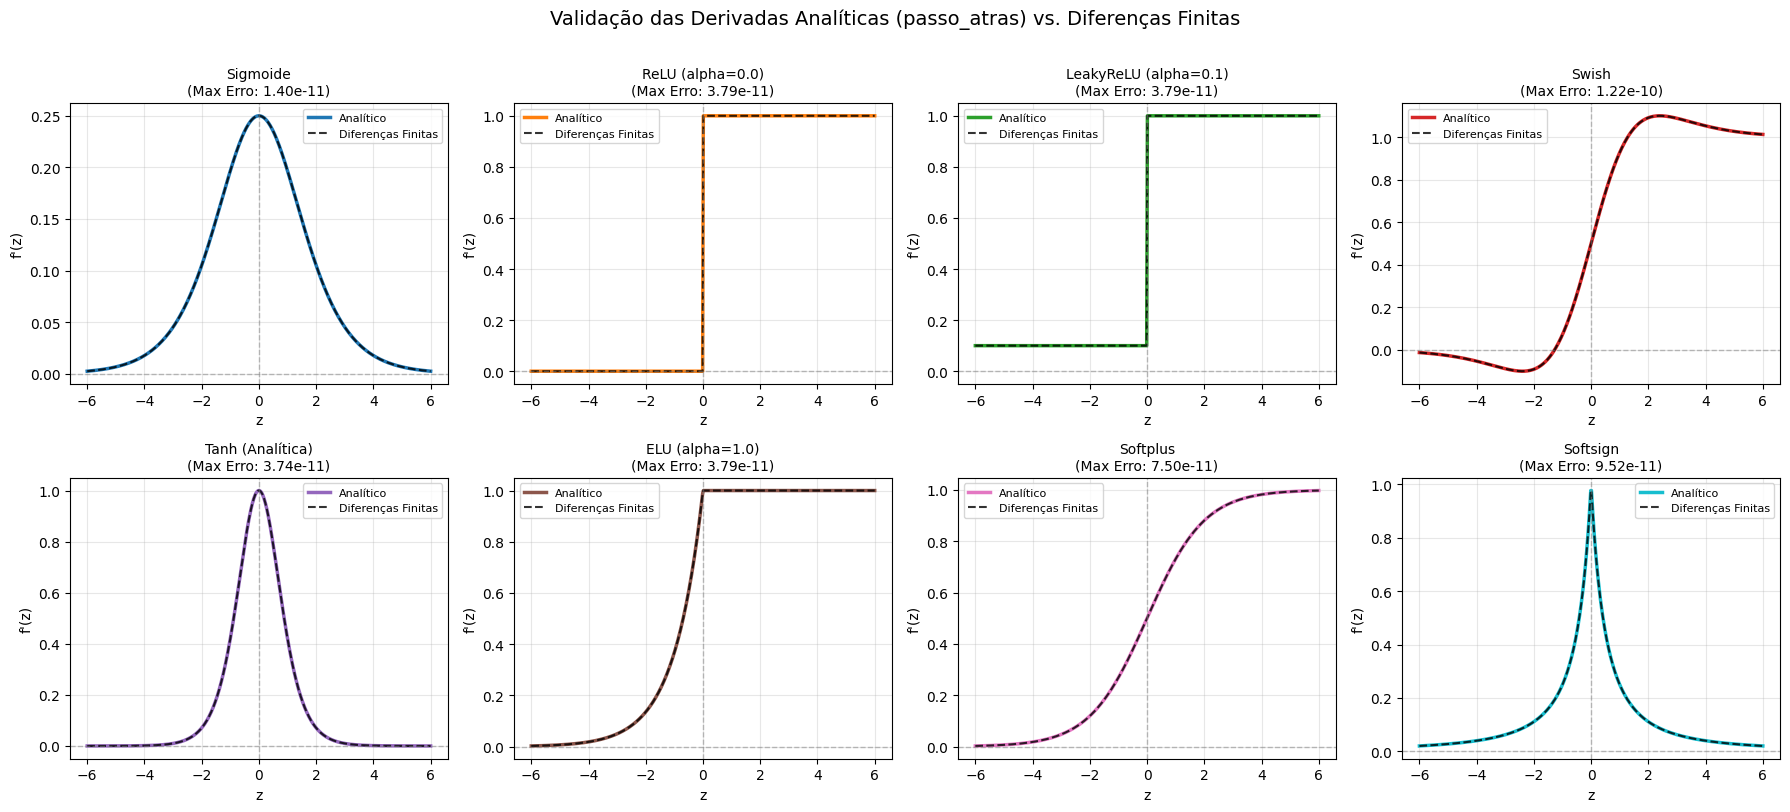

,Função,Max Erro Absoluto,Erro Médio Absoluto,Concordância
0,Sigmoide,1.40e-11,2.30e-12,Excelente (< 1e-5)
1,ReLU (alpha=0.0),3.79e-11,8.21e-12,Excelente (< 1e-5)
2,LeakyReLU (alpha=0.1),3.79e-11,9.03e-12,Excelente (< 1e-5)
3,Swish,1.22e-10,1.10e-11,Excelente (< 1e-5)
4,Tanh (Analítica),3.74e-11,7.81e-12,Excelente (< 1e-5)
5,ELU (alpha=1.0),3.79e-11,1.01e-11,Excelente (< 1e-5)
6,Softplus,7.50e-11,9.17e-12,Excelente (< 1e-5)
7,Softsign,9.52e-11,7.33e-12,Excelente (< 1e-5)


In [6]:
eps = 1e-5
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()
linhas_erro = []

for ax, (nome, ativ) in zip(axes, ativacoes_1d.items(), strict=True):
    ativ.passo_a_frente(z)
    grad_analitico = ativ.passo_atras(np.ones_like(z))

    f_mais = ativ.passo_a_frente(z + eps)
    f_menos = ativ.passo_a_frente(z - eps)
    grad_numerico = (f_mais - f_menos) / (2 * eps)

    erro_abs = np.abs(grad_analitico - grad_numerico)
    max_erro = np.max(erro_abs)

    linhas_erro.append(
        {
            "Função": nome,
            "Max Erro Absoluto": f"{max_erro:.2e}",
            "Erro Médio Absoluto": f"{np.mean(erro_abs):.2e}",
            "Concordância": "Excelente (< 1e-5)" if max_erro < 1e-4 else "Atenção",
        }
    )

    ax.plot(z, grad_analitico, lw=2.5, color=cores[nome], label="Analítico")
    ax.plot(z, grad_numerico, "k--", lw=1.5, alpha=0.8, label="Diferenças Finitas")
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5, lw=1)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.5, lw=1)
    ax.set_title(f"{nome}\n(Max Erro: {max_erro:.2e})", fontsize=10)
    ax.set_xlabel("z")
    ax.set_ylabel("f'(z)")
    ax.legend(loc="best", fontsize=8)

plt.suptitle("Validação das Derivadas Analíticas (passo_atras) vs. Diferenças Finitas", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

pd.DataFrame(linhas_erro)


## 3. Teste de Estabilidade Numérica contra Overflow / Underflow

Abaixo submetemos cada função a entradas de magnitude extrema ($z \in [-1000, 1000]$) para verificar a robustez das formulações implementadas:
- **Sigmoide, Swish, Tanh**: Baseadas na decomposição da sigmoide estável por sinal de $z$.
- **Softplus**: Utiliza `max(z, 0) + log1p(exp(-|z|))` para não estourar em exponenciais positivas grandes.
- **ELU**: Limita expoentes com `minimum(z, 0)` para que $e^z \le 1$ sempre.
- **Softsign**: Não possui exponenciais, naturalmente imune a overflow.
- **Softmax**: Subtrai $\max(z)$ de cada vetor antes da exponenciação ($z_i - \max(z)$).


In [7]:
z_extremo = np.array([-1000.0, -500.0, -100.0, 0.0, 100.0, 500.0, 1000.0])
resumo_estabilidade = []

for nome, ativ in ativacoes_1d.items():
    a = ativ.passo_a_frente(z_extremo)
    grad = ativ.passo_atras(np.ones_like(a))

    resumo_estabilidade.append(
        {
            "Ativação": nome,
            "Contém NaN": bool(np.any(np.isnan(a)) or np.any(np.isnan(grad))),
            "Contém Inf": bool(np.any(np.isinf(a)) or np.any(np.isinf(grad))),
            "f(-1000)": f"{a[0]:.2f}",
            "f(0)": f"{a[3]:.2f}",
            "f(+1000)": f"{a[-1]:.2f}",
            "Status": "Estável" if not np.any(np.isnan(a) | np.isinf(a)) else "Instável",
        }
    )

# Softmax com entradas extremas
softmax = Softmax()
z_extremo_softmax = np.array(
    [
        [1000.0, 1001.0, 1002.0],
        [-1000.0, -1000.0, -1000.0],
        [1e5, 1e5 + 1.0, 1e5 + 2.0],
    ]
)
a_sm = softmax.passo_a_frente(z_extremo_softmax)
grad_sm = softmax.passo_atras(np.ones_like(a_sm))

resumo_estabilidade.append(
    {
        "Ativação": "Softmax",
        "Contém NaN": bool(np.any(np.isnan(a_sm)) or np.any(np.isnan(grad_sm))),
        "Contém Inf": bool(np.any(np.isinf(a_sm)) or np.any(np.isinf(grad_sm))),
        "f(-1000)": f"soma={np.sum(a_sm[1]):.2f}",
        "f(0)": f"soma={np.sum(a_sm[0]):.2f}",
        "f(+1000)": f"soma={np.sum(a_sm[2]):.2f}",
        "Status": "Estável (via z - max(z))",
    }
)

pd.DataFrame(resumo_estabilidade)


,Ativação,Contém NaN,Contém Inf,f(-1000),f(0),f(+1000),Status
0,Sigmoide,False,False,0.00,0.50,1.00,Estável
1,ReLU (alpha=0.0),False,False,-0.00,0.00,1000.00,Estável
2,LeakyReLU (alpha=0.1),False,False,-100.00,0.00,1000.00,Estável
3,Swish,False,False,-0.00,0.00,1000.00,Estável
4,Tanh (Analítica),False,False,-1.00,0.00,1.00,Estável
5,ELU (alpha=1.0),False,False,-1.00,0.00,1000.00,Estável
6,Softplus,False,False,0.00,0.69,1000.00,Estável
7,Softsign,False,False,-1.00,0.00,1.00,Estável
8,Softmax,False,False,soma=1.00,soma=1.00,soma=1.00,Estável (via z - max(z))


## 4. Softmax para Classificação Multiclasse e Retropropagação

A função **Softmax** converte um vetor de pontuações arbitrárias (logits $z_i$) em uma distribuição de probabilidade normalizada sobre $C$ classes:
$$S(z_i) = \frac{\exp(z_i - \max(z))}{\sum_{j=1}^C \exp(z_j - \max(z))}, \quad \sum_{i=1}^C S(z_i) = 1.0$$

### Retropropagação Analítica Otimizada $O(C)$:
A derivada da perda $L$ em relação ao logit $z_i$ dada a derivada em relação à probabilidade $\frac{\partial L}{\partial S_i}$ é dada pelo produto vetor-Jacobiana:
$$\frac{\partial L}{\partial z_i} = S_i \left( \frac{\partial L}{\partial S_i} - \sum_{j=1}^C \frac{\partial L}{\partial S_j} S_j \right)$$
Esta formulação otimizada evita instanciar e multiplicar explicitamente a matriz Jacobiana densa $C \times C$ ($J_{ij} = S_i(\delta_{ij} - S_j)$), reduzindo a complexidade computacional e de memória de $O(C^2)$ para $O(C)$ por amostra.


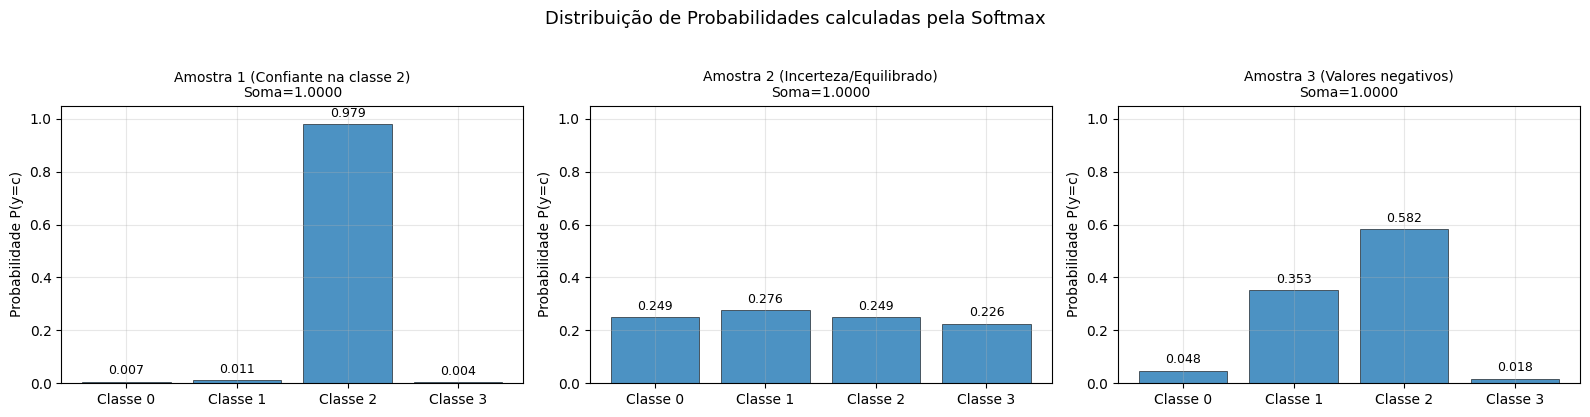

Verificação do Gradiente da Softmax:
-> Gradiente via passo_atras (O(C)):         [-0.029477 -0.152141 -0.009104  0.190723]
-> Gradiente via produto Jacobiana (O(C^2)): [-0.029477 -0.152141 -0.009104  0.190723]
-> Concordância exata confirmada!


In [8]:
softmax = Softmax()

exemplos_logits = {
    "Amostra 1 (Confiante na classe 2)": np.array([[1.0, 1.5, 6.0, 0.5]]),
    "Amostra 2 (Incerteza/Equilibrado)": np.array([[2.0, 2.1, 2.0, 1.9]]),
    "Amostra 3 (Valores negativos)": np.array([[-3.0, -1.0, -0.5, -4.0]]),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
classes = ["Classe 0", "Classe 1", "Classe 2", "Classe 3"]

for ax, (titulo, logits) in zip(axes, exemplos_logits.items(), strict=True):
    probs = softmax.passo_a_frente(logits)[0]
    bars = ax.bar(classes, probs, color="#1f77b4", alpha=0.8, edgecolor="black", linewidth=0.5)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{titulo}\nSoma={np.sum(probs):.4f}", fontsize=10)
    ax.set_ylabel("Probabilidade P(y=c)")

    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{h:.3f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

plt.suptitle("Distribuição de Probabilidades calculadas pela Softmax", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

# Validação da Retropropagação Otimizada vs Jacobiana Completa
z_teste = np.array([[0.5, 1.2, -0.3, 2.5]])
probs_teste = softmax.passo_a_frente(z_teste)[0]
grad_saida_teste = np.array([[0.1, -0.4, 0.2, 0.7]])

# 1. Backward analítico implementado (vetor-Jacobiana O(C))
grad_implementado = softmax.passo_atras(grad_saida_teste)[0]

# 2. Jacobiana completa J_{ij} = S_i * (delta_{ij} - S_j) (O(C^2))
J = np.diag(probs_teste) - np.outer(probs_teste, probs_teste)
grad_jacobiana = grad_saida_teste[0] @ J

print("Verificação do Gradiente da Softmax:")
print(f"-> Gradiente via passo_atras (O(C)):         {np.round(grad_implementado, 6)}")
print(f"-> Gradiente via produto Jacobiana (O(C^2)): {np.round(grad_jacobiana, 6)}")
np.testing.assert_allclose(grad_implementado, grad_jacobiana, rtol=1e-7)
print("-> Concordância exata confirmada!")
